<a href="https://colab.research.google.com/github/pedroUDF/ciencia_dados_maquina/blob/main/Projeto_DataScience/notebooks/modelagem_avaliacao_fase5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

AVALIAÇÃO TÉCNICA E DE NEGÓCIO

--- 1. ANÁLISE DE SENSIBILIDADE DO LIMIAR DE DECISÃO (GRADIENT BOOSTING) ---
 Limiar (Threshold)  ROC-AUC  Recall (%)  Precision (%)  F1-Score  Acionados (% da Base)
               0.55   0.7205       63.94          47.87    0.5475                  41.42
               0.50   0.7205       69.59          46.23    0.5555                  46.67
               0.48   0.7205       71.29          45.51    0.5555                  48.58
               0.45   0.7205       74.81          44.50    0.5581                  52.12
               0.42   0.7205       78.44          43.24    0.5575                  56.25

--- 2. MATRIZ DE CONFUSÃO (LIMIAR OPERACIONAL = 0.48) ---
Verdadeiros Negativos (Presentes previstos corretamente): 6,196
Falsos Positivos (Presentes acionados preventivamente):    3,857
Falsos Negativos (Abstentes não detectados):             1,297
Verdadeiros Positivos (Abstentes capturados pelo modelo):3,221

--- 3. SIMULAÇÃO DE IMPACTO OPERACIONAL NO

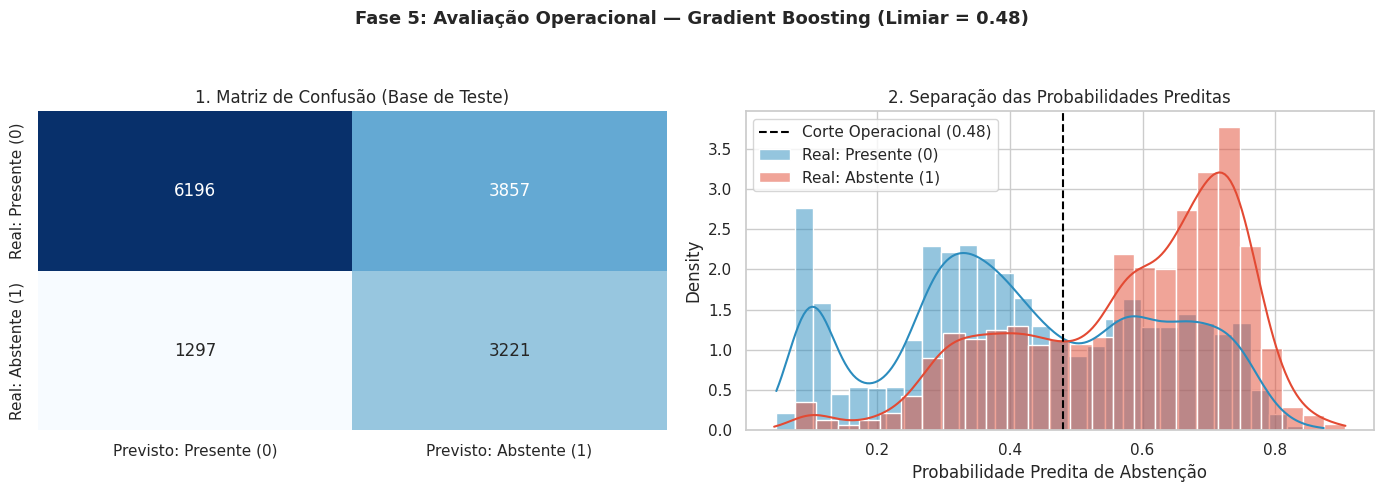

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (
    confusion_matrix, classification_report, roc_auc_score,
    recall_score, precision_score, f1_score
)

print("AVALIAÇÃO TÉCNICA E DE NEGÓCIO\n")

# 1. Carregar e preparar o Dataset B (Socioeconômico 2023) diretamente do GitHub
base_url = "https://raw.githubusercontent.com/pedroUDF/ciencia_dados_maquina/main/Projeto_DataScience/data/processed"
df_2023 = pd.read_parquet(f"{base_url}/2023_completo_df.parquet")

d23 = df_2023[~((df_2023["TP_PRESENCA_CH"] == 2) | (df_2023["TP_PRESENCA_MT"] == 2))].copy()
d23["ABSTENCAO"] = ((d23["TP_PRESENCA_CH"] == 0) | (d23["TP_PRESENCA_MT"] == 0)).astype(int)
d23["POSSUI_ESCOLA_VINCULADA"] = d23["TP_DEPENDENCIA_ADM_ESC"].notna().astype(int)
d23["ESTUDA_FORA_DF"] = (d23["SG_UF_ESC"].notna() & (d23["SG_UF_ESC"] != "DF")).astype(int)
d23["REDE_ESCOLAR"] = d23["TP_DEPENDENCIA_ADM_ESC"].fillna(0).astype(int)
d23["EGRESSO_FORA_FLUXO"] = d23["TP_ST_CONCLUSAO"].isin([1, 4]).astype(int)

mapa_renda = {l: i for i, l in enumerate(list("ABCDEFGHIJKLMNOPQ"))}
mapa_esc = {"A": 0, "B": 1, "C": 2, "D": 3, "E": 4, "F": 5, "G": 6, "H": -1}
mapa_bens = {"A": 0, "B": 1, "C": 2, "D": 3, "E": 4}

d23["RENDA_ORDINAL"] = d23["Q006"].map(mapa_renda)
d23["ESC_PAI_ORDINAL"] = d23["Q001"].map(mapa_esc)
d23["ESC_MAE_ORDINAL"] = d23["Q002"].map(mapa_esc)
d23["QTD_COMPUTADORES"] = d23["Q024"].map(mapa_bens)
d23["ACESSO_INTERNET"] = (d23["Q025"] == "B").astype(int)
d23["SEXO_MASC"] = (d23["TP_SEXO"] == "M").astype(int)

cols_B = [
    "TP_FAIXA_ETARIA", "SEXO_MASC", "TP_ESTADO_CIVIL", "TP_COR_RACA", "TP_ST_CONCLUSAO",
    "IN_TREINEIRO", "POSSUI_ESCOLA_VINCULADA", "ESTUDA_FORA_DF", "EGRESSO_FORA_FLUXO",
    "REDE_ESCOLAR", "TP_LINGUA", "RENDA_ORDINAL", "ESC_PAI_ORDINAL", "ESC_MAE_ORDINAL",
    "QTD_COMPUTADORES", "ACESSO_INTERNET", "ABSTENCAO"
]
df_b_enc = pd.get_dummies(d23[cols_B], columns=["TP_ESTADO_CIVIL", "TP_COR_RACA", "TP_ST_CONCLUSAO", "REDE_ESCOLAR"], dtype=int)
train_B, test_B = train_test_split(df_b_enc, test_size=0.20, random_state=42, stratify=df_b_enc["ABSTENCAO"])

X_train_B, y_train_B = train_B.drop(columns=["ABSTENCAO"]), train_B["ABSTENCAO"]
X_test_B, y_test_B = test_B.drop(columns=["ABSTENCAO"]), test_B["ABSTENCAO"]

# Treina o modelo campeão da Fase 4: Gradient Boosting (HistGB)
modelo_campeao = HistGradientBoostingClassifier(
    max_iter=200, max_depth=6, learning_rate=0.05, class_weight="balanced", random_state=42
)
modelo_campeao.fit(X_train_B, y_train_B)
y_prob_B = modelo_campeao.predict_proba(X_test_B)[:, 1]

# Análise de Sensibilidade do Limiar (Threshold Tuning)
limiares = [0.55, 0.50, 0.48, 0.45, 0.42]
tabela_limiares = []

for th in limiares:
    y_pred_th = (y_prob_B >= th).astype(int)
    tabela_limiares.append({
        "Limiar (Threshold)": th,
        "ROC-AUC": round(roc_auc_score(y_test_B, y_prob_B), 4),
        "Recall (%)": round(recall_score(y_test_B, y_pred_th) * 100, 2),
        "Precision (%)": round(precision_score(y_test_B, y_pred_th) * 100, 2),
        "F1-Score": round(f1_score(y_test_B, y_pred_th), 4),
        "Acionados (% da Base)": round(y_pred_th.mean() * 100, 2)
    })

df_th = pd.DataFrame(tabela_limiares)
print("--- 1. ANÁLISE DE SENSIBILIDADE DO LIMIAR DE DECISÃO (GRADIENT BOOSTING) ---")
print(df_th.to_string(index=False))

# Avaliação no Limiar Operacional Escolhido (0.48)
limiar_otimo = 0.48
y_pred_otimo = (y_prob_B >= limiar_otimo).astype(int)
cm = confusion_matrix(y_test_B, y_pred_otimo)
tn, fp, fn, tp = cm.ravel()

print(f"\n--- 2. MATRIZ DE CONFUSÃO (LIMIAR OPERACIONAL = {limiar_otimo}) ---")
print(f"Verdadeiros Negativos (Presentes previstos corretamente): {tn:,}")
print(f"Falsos Positivos (Presentes acionados preventivamente):    {fp:,}")
print(f"Falsos Negativos (Abstentes não detectados):             {fn:,}")
print(f"Verdadeiros Positivos (Abstentes capturados pelo modelo):{tp:,}")

# Simulação de Impacto de Negócio no DF (cenário 82.955 inscritos de 2025)
total_df_2025 = 82955
taxa_abst_real = 0.3163
abstentes_reais_df = int(total_df_2025 * taxa_abst_real)
recall_final = recall_score(y_test_B, y_pred_otimo)
abstentes_capturados = int(abstentes_reais_df * recall_final)
reducao_10pct = int(abstentes_capturados * 0.10)  # Meta de negócio da Fase 1: recuperar 10% do grupo de risco

print("\n--- 3. SIMULAÇÃO DE IMPACTO OPERACIONAL NO DF (CENÁRIO 82.955 INSCRITOS) ---")
print(f"Total estimado de abstentes no DF sem intervenção: {abstentes_reais_df:,} candidatos")
print(f"Abstentes identificados antecipadamente (Recall {recall_final*100:.1f}%): {abstentes_capturados:,} candidatos")
print(f"Candidatos recuperados com campanha focalizada (10% de conversão): +{reducao_10pct:,} presentes na prova")

# Painel Visual
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle(f"Fase 5: Avaliação Operacional — Gradient Boosting (Limiar = {limiar_otimo})", fontsize=13, fontweight="bold")

sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0],
    xticklabels=["Previsto: Presente (0)", "Previsto: Abstente (1)"],
    yticklabels=["Real: Presente (0)", "Real: Abstente (1)"]
)
axes[0].set_title("1. Matriz de Confusão (Base de Teste)")

sns.histplot(y_prob_B[y_test_B == 0], color="#2b8cbe", label="Real: Presente (0)", kde=True, stat="density", alpha=0.5, ax=axes[1])
sns.histplot(y_prob_B[y_test_B == 1], color="#e34a33", label="Real: Abstente (1)", kde=True, stat="density", alpha=0.5, ax=axes[1])
axes[1].axvline(limiar_otimo, color="black", linestyle="--", lw=1.5, label=f"Corte Operacional ({limiar_otimo})")
axes[1].set_title("2. Separação das Probabilidades Preditas")
axes[1].set_xlabel("Probabilidade Predita de Abstenção")
axes[1].legend()

plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()